# House Price Prediction
## Notebook 5 — Final Evaluation and Model Export
**Author: Tinashe Clifford Makandise**

## 1. Final evaluation protocol
Notebook 4 selected the configuration using training-only cross-validation. This notebook fits that frozen configuration on the full training partition and evaluates the reserved test partition. Model settings and feature definitions are not changed in response to test performance.

Primary metric: **MAE in historical USD**. Supporting metrics: RMSE, R², median absolute error and signed prediction bias. Compare with a median-price baseline fitted on training data. Inspect residuals, price-range errors and neighbourhood errors descriptively. No row is removed and no prediction is clipped.

The exported pipeline remains trained on the original training partition, so its reported test scores refer to that exact model. The test set is not added to fitting.

### Prerequisites
Run Notebooks 1, 3 and 4 in order. This notebook requires their data partitions, manifest, shared `src` package and selected configuration/template. Install if needed: `%pip install pandas numpy scikit-learn matplotlib joblib`. Save this notebook in `notebooks/`. Only load joblib files from trusted sources.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, subprocess
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.features import RAW_CORE, build_features
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
manifest = json.loads((REPORTS_DIR / "data_manifest.json").read_text(encoding="utf-8"))
selection = json.loads((REPORTS_DIR / "selected_model_config.json").read_text(encoding="utf-8"))
train_path = PROJECT_ROOT / "data/processed/train.csv"
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == selection["train_sha256"], "Training file changed; resolve provenance before evaluating."
assert selection["test_data_used"] is False
assert sklearn.__version__ == selection["versions"]["sklearn"], "Use the training scikit-learn version or rerun Notebook 4 in this environment."
train = pd.read_csv(train_path, keep_default_na=False, na_values=[""])
test = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv", keep_default_na=False, na_values=[""])
assert train["PID"].is_unique and test["PID"].is_unique
assert set(train["PID"].astype(int)) == set(manifest["train_pids"])
assert set(test["PID"].astype(int)) == set(manifest["test_pids"])
assert set(train["PID"]).isdisjoint(test["PID"])
assert len(train) == manifest["train_rows"] and len(test) == manifest["test_rows"]
assert train["SalePrice"].gt(0).all() and test["SalePrice"].gt(0).all()
X_train, y_train = train.drop(columns="SalePrice"), train["SalePrice"]
X_test, y_test = test.drop(columns="SalePrice"), test["SalePrice"]
print("Frozen candidate:", selection["candidate"])
print(f"Training: {len(train):,}; held-out evaluation: {len(test):,} properties.")

Frozen candidate: Forest leaf=1 | expanded
Training: 2,344; held-out evaluation: 586 properties.


## 2. Fit the frozen model and training baseline
Cloning clears any fitted state in the saved template. Feature engineering and preprocessing remain inside the model pipeline, which learns only from training properties. Baseline predictions use the training median, not the test median. The selected model is evaluated without further search.

In [2]:
template = joblib.load(MODELS_DIR / "selected_model_template.joblib")
model = clone(template)
model.fit(X_train, y_train)
predictions = np.asarray(model.predict(X_test), dtype=float)
baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
assert predictions.shape == (len(test),) and np.isfinite(predictions).all()
print("Fitted frozen model and baseline using training rows only.")

Fitted frozen model and baseline using training rows only.


## 3. Held-out metrics
MAE is the average absolute price error, not an uncertainty interval for an individual house. RMSE penalises large errors more heavily. R² measures reduction in squared error relative to the test-mean reference; it is not the fraction of correct predictions. Positive signed bias means overprediction. These statistics describe this finite historical holdout.

In [3]:
def evaluate(actual, predicted):
    return {"mae": float(mean_absolute_error(actual, predicted)),
            "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
            "r2": float(r2_score(actual, predicted)),
            "median_absolute_error": float(median_absolute_error(actual, predicted)),
            "mean_signed_error": float(np.mean(predicted - actual))}
model_metrics = evaluate(y_test, predictions)
baseline_metrics = evaluate(y_test, baseline_predictions)
metrics_table = pd.DataFrame({"Selected model": model_metrics, "Training median baseline": baseline_metrics}).T
improvement = 100 * (baseline_metrics["mae"] - model_metrics["mae"]) / baseline_metrics["mae"]
display(metrics_table.round(3))
print(f"Holdout MAE improvement versus baseline: {improvement:.1f}%")
print(f"Selection CV MAE: ${selection['cv_mae']:,.0f}; holdout MAE: ${model_metrics['mae']:,.0f}")

                                mae       rmse     r2  median_absolute_error  mean_signed_error
Selected model            19311.066  32791.894  0.866               12437.26           -891.702
Training median baseline  63838.101  94322.625 -0.110               40300.00         -29651.469
Holdout MAE improvement versus baseline: 69.7%
Selection CV MAE: $19,053; holdout MAE: $19,311


## 4. Residual diagnostics
Residual is defined as **actual minus predicted**. Positive residuals indicate underprediction; negative residuals indicate overprediction. An ideal actual-versus-predicted plot lies near the diagonal. Large residuals remain part of the reported performance. Patterns diagnose limitations; they will not be used to retune this model against the holdout.

Ten largest absolute errors — retained in all metrics:
           PID Neighborhood  Gr Liv Area  Overall Qual  actual_price  predicted_price   residual  absolute_error
433  908154205      Edwards         4676            10        184750        554109.99 -369359.99       369359.99
5    528150070      NridgHt         2364             9        611657        434285.94  177371.06       177371.06
91   528110020      NridgHt         2674            10        610000        453488.99  156511.01       156511.01
194  527212050      StoneBr         2504             9        325000        459984.15 -134984.15       134984.15
89   528106020      NridgHt         2402            10        555000        421731.52  133268.48       133268.48
92   528110090      NridgHt         2822             9        582933        461288.39  121644.61       121644.61
445  911370460      Crawfor         1625             8        235000        349481.90 -114481.90       114481.90
325  527256030      StoneBr         2234 

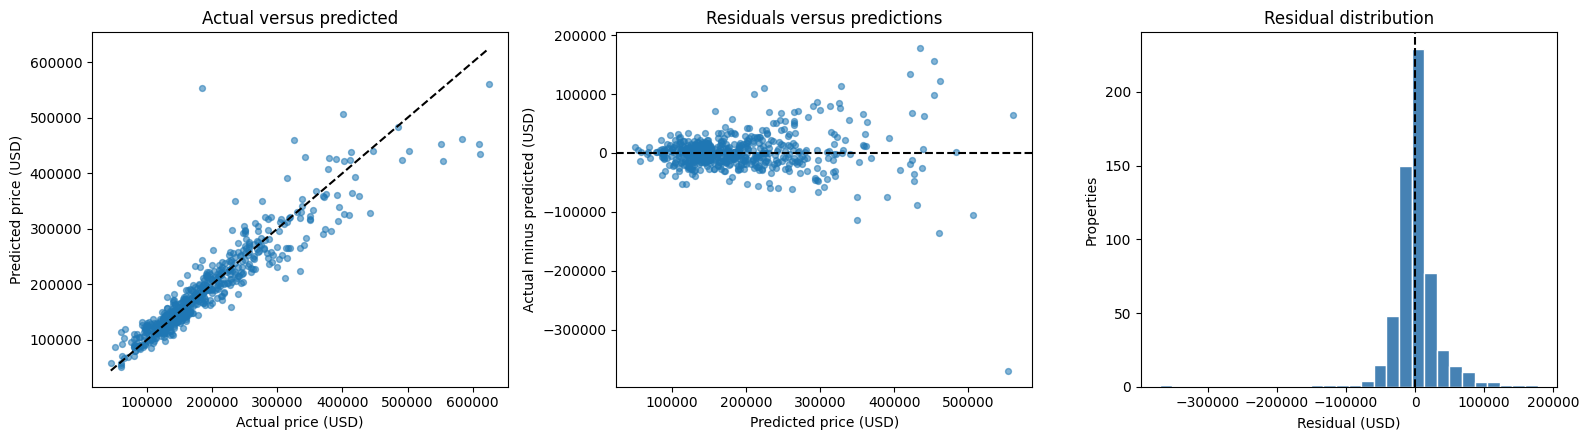

In [4]:
results = test[["PID", "Neighborhood", "Gr Liv Area", "Overall Qual"]].copy()
results["actual_price"] = y_test.to_numpy()
results["predicted_price"] = predictions
results["residual"] = results["actual_price"] - results["predicted_price"]
results["absolute_error"] = results["residual"].abs()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, predictions, s=18, alpha=.55)
lo = min(y_test.min(), predictions.min()); hi = max(y_test.max(), predictions.max())
axes[0].plot([lo, hi], [lo, hi], color="black", linestyle="--")
axes[0].set(xlabel="Actual price (USD)", ylabel="Predicted price (USD)", title="Actual versus predicted")
axes[1].scatter(predictions, results["residual"], s=18, alpha=.55)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted price (USD)", ylabel="Actual minus predicted (USD)", title="Residuals versus predictions")
axes[2].hist(results["residual"], bins=30, color="steelblue", edgecolor="white")
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set(xlabel="Residual (USD)", ylabel="Properties", title="Residual distribution")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_test_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print("Ten largest absolute errors — retained in all metrics:")
display(results.nlargest(10, "absolute_error"))

## 5. Error patterns across property groups
Price groups use boundaries computed from training-price quartiles. Their holdout membership uses actual sale prices and is strictly a retrospective diagnostic, not an input available when predicting a new property. Neighbourhood groups can be very small; show counts and avoid strong conclusions about sparse groups.

These summaries do not establish fairness or reliable performance in unrepresented locations. No group is excluded and the model is not changed after this inspection.

In [5]:
quartiles = y_train.quantile([.25, .5, .75]).to_numpy()
results["price_band"] = pd.cut(results["actual_price"], bins=[-np.inf, *quartiles, np.inf],
                               labels=["Lowest training-price quarter", "Lower middle", "Upper middle", "Highest training-price quarter"])
def group_summary(frame, column):
    return frame.groupby(column, observed=True).agg(
        count=("absolute_error", "size"), mae=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_residual=("residual", "mean"))
price_errors = group_summary(results, "price_band")
neighborhood_errors = group_summary(results, "Neighborhood").sort_values("count", ascending=False)
neighborhood_errors["small_sample_under_10"] = neighborhood_errors["count"] < 10
display(price_errors.round(2))
display(neighborhood_errors.round(2))
unknown_neighborhood_count = int((~test["Neighborhood"].isin(train["Neighborhood"].unique())).sum())
print("Test properties with neighbourhood absent from training:", unknown_neighborhood_count)

                                count       mae  median_absolute_error  mean_residual
price_band                                                                           
Lowest training-price quarter     139  11833.71                9188.11       -6629.33
Lower middle                      142  11263.04                9131.75        -781.10
Upper middle                      122  16818.69               10230.31       -6107.99
Highest training-price quarter    183  32897.08               24304.90       12568.88
              count       mae  median_absolute_error  mean_residual  small_sample_under_10
Neighborhood                                                                              
NAmes            76  10235.64                6747.79        -328.62                  False
CollgCr          56  16996.64               12640.73       -2829.75                  False
Somerst          46  16264.79                9840.89        6899.97                  False
NridgHt          45  40958.91

## 6. Explain model use of inputs
For the selected forest, aggregate impurity-based importance over one-hot neighbourhood columns. This describes split usage in the training-fitted forest, not causal price contributions or an explanation of an individual prediction. Such importance can favour variables with many possible splits and distribute signal among correlated features. It must not be used to prune features after inspecting holdout results. Other model families skip this forest-specific diagnostic.

               importance
feature                  
Overall Qual     0.631693
Gr Liv Area      0.183725
AgeAtSale        0.052899
Neighborhood     0.040455
Garage Cars      0.034896
Full Bath        0.023147
Bedroom AbvGr    0.015765
Overall Cond     0.011069
Half Bath        0.006350


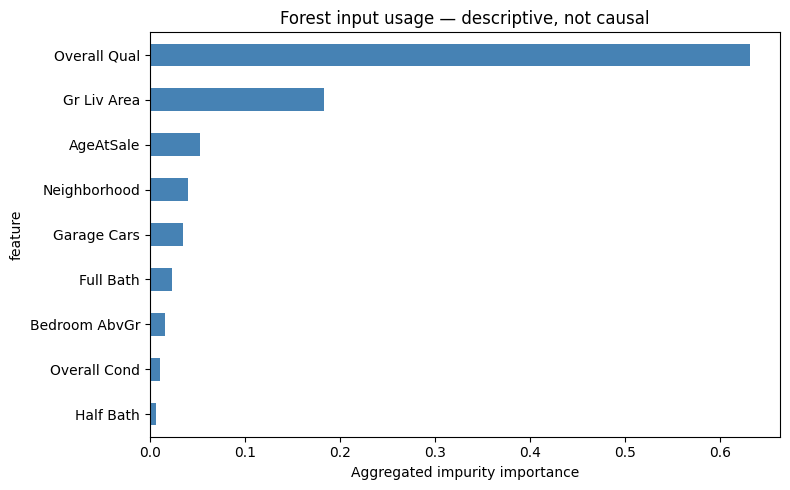

In [6]:
feature_importance = pd.DataFrame()
if hasattr(model, "named_steps") and hasattr(model.named_steps["model"], "feature_importances_"):
    names = model.named_steps["preprocess"].get_feature_names_out()
    values = model.named_steps["model"].feature_importances_
    feature_importance = pd.DataFrame({"encoded_feature": names, "importance": values})
    feature_importance["feature"] = feature_importance["encoded_feature"].map(
        lambda name: "Neighborhood" if name.startswith("categorical__") else name.split("__", 1)[-1])
    grouped_importance = feature_importance.groupby("feature")["importance"].sum().sort_values()
    grouped_importance.plot.barh(figsize=(8, 5), color="steelblue")
    plt.xlabel("Aggregated impurity importance")
    plt.title("Forest input usage — descriptive, not causal")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "05_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(grouped_importance.sort_values(ascending=False).to_frame())
else:
    print("Forest impurity importance does not apply to the selected estimator.")

## 7. Export and verify the fitted prediction pipeline
The full pipeline includes feature construction, imputation, encoding and the fitted estimator. Export the exact evaluated model without adding test rows to training. Metadata records metrics, input requirements, supported training locations, historical scope and package versions.

A fresh Python process must load the artifact and reproduce predictions using only the required input columns. Keep `src/` beside the eventual app and use matching package versions. The example input below is a training property; its file contains only predictor fields.

In [7]:
model_path = MODELS_DIR / "house_price_pipeline.joblib"
joblib.dump(model, model_path)
required_inputs = RAW_CORE + (["Overall Qual", "Overall Cond"] if selection["configuration"].get("expanded") else [])
example = X_train[required_inputs].iloc[[0]].copy()
example_path = REPORTS_DIR / "example_property.json"
example.to_json(example_path, orient="records", indent=2)
expected_example = model.predict(example)
loaded = joblib.load(model_path)
np.testing.assert_allclose(loaded.predict(X_test[required_inputs]), predictions)
verification_script = 'import sys, json, joblib, pandas as pd\nfrom pathlib import Path\nroot = Path(sys.argv[1])\nsys.path.insert(0, str(root))\nmodel = joblib.load(root / "models/house_price_pipeline.joblib")\nframe = pd.read_json(root / "reports/example_property.json", orient="records")\nprint(json.dumps(model.predict(frame).tolist()))\n'
completed = subprocess.run([sys.executable, "-c", verification_script, str(PROJECT_ROOT)],
                           check=True, capture_output=True, text=True)
np.testing.assert_allclose(np.array(json.loads(completed.stdout)), expected_example)
metadata = {
    "author": "Tinashe Clifford Makandise", "created_utc": datetime.now(timezone.utc).isoformat(),
    "candidate": selection["candidate"], "configuration": selection["configuration"],
    "target": "SalePrice", "currency": "USD", "scope": "Ames, Iowa; historical 2006–2010 sale prices",
    "train_rows": len(train), "test_rows": len(test), "training_includes_test": False,
    "required_raw_inputs": required_inputs, "age_definition": "Yr Sold minus Year Built; negative ages become missing",
    "supported_neighborhoods": sorted(train["Neighborhood"].dropna().unique().tolist()),
    "sale_year_options": sorted(train["Yr Sold"].unique().astype(int).tolist()),
    "test_metrics": model_metrics, "baseline_test_metrics": baseline_metrics,
    "cv_mae": selection["cv_mae"], "holdout_mae_improvement_percent": float(improvement),
    "unknown_test_neighborhood_count": unknown_neighborhood_count,
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
    "train_sha256": hashlib.sha256(train_path.read_bytes()).hexdigest(),
    "test_sha256": hashlib.sha256((PROJECT_ROOT / "data/processed/test.csv").read_bytes()).hexdigest(),
    "source_sha256": manifest["source_sha256"],
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit_learn": sklearn.__version__, "joblib": joblib.__version__},
    "limitations": ["Historical educational demonstration, not current valuation", "Not validated outside Ames",
                    "MAE is not a prediction interval", "Sparse and unusual properties may have larger errors"],
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(REPORTS_DIR / "test_metrics.json").write_text(json.dumps({"model": model_metrics, "baseline": baseline_metrics}, indent=2), encoding="utf-8")
metrics_table.to_csv(REPORTS_DIR / "test_metric_comparison.csv", index_label="model")
results.to_csv(REPORTS_DIR / "test_predictions.csv", index=False)
price_errors.to_csv(REPORTS_DIR / "test_errors_by_price_band.csv")
neighborhood_errors.to_csv(REPORTS_DIR / "test_errors_by_neighborhood.csv")
if not feature_importance.empty:
    feature_importance.to_csv(REPORTS_DIR / "forest_feature_importance.csv", index=False)
print("Fitted pipeline exported; same-process and fresh-process predictions match.")

Fitted pipeline exported; same-process and fresh-process predictions match.


## 8. Results and conclusion
The generated summary below states results from the current evaluation. The model has been frozen; no test-driven tuning follows. This completes the five-notebook modelling workflow. Remaining project work is to build and validate the Streamlit interface, prepare reproducible training code and documentation, and package the application.

In [8]:
summary = [
    f"Selected model: {selection['candidate']}",
    f"Training properties: {len(train):,}; held-out properties: {len(test):,}.",
    f"Test MAE: ${model_metrics['mae']:,.0f}; RMSE: ${model_metrics['rmse']:,.0f}; R²: {model_metrics['r2']:.3f}.",
    f"Baseline test MAE: ${baseline_metrics['mae']:,.0f}; MAE reduction: {improvement:.1f}%.",
    f"Median absolute error: ${model_metrics['median_absolute_error']:,.0f}.",
    "The exported pipeline is trained on training rows only and has passed fresh-process loading verification.",
    "These results apply to the historical Ames holdout, not present-day property values or other markets.",
]
print("\n".join(summary))
(REPORTS_DIR / "final_evaluation_summary.txt").write_text("\n".join(summary), encoding="utf-8")

Selected model: Forest leaf=1 | expanded
Training properties: 2,344; held-out properties: 586.
Test MAE: $19,311; RMSE: $32,792; R²: 0.866.
Baseline test MAE: $63,838; MAE reduction: 69.7%.
Median absolute error: $12,437.
The exported pipeline is trained on training rows only and has passed fresh-process loading verification.
These results apply to the historical Ames holdout, not present-day property values or other markets.


## 9. Files and application handover
- `models/house_price_pipeline.joblib`: fitted, evaluated pipeline.
- `models/model_metadata.json`: schema, provenance, scope and metrics.
- `reports/test_metrics.json`, `test_metric_comparison.csv`, `test_predictions.csv`: evaluation evidence.
- `reports/test_errors_by_price_band.csv` and `test_errors_by_neighborhood.csv`: diagnostic groups.
- `reports/example_property.json`: predictor-only loading example.
- `reports/figures/05_*.png`: diagnostic charts.

**Streamlit requirements:** load the saved pipeline once, present supported neighbourhood choices, label units and above-ground rooms clearly, collect quality/condition for the expanded model, use an explicit historical sale year, validate inputs, and call `predict()` with named raw columns. Display historical USD and the model scope. Do not display an invented confidence percentage or imply a guaranteed error bound.

Rerunning this notebook reproduces evaluation of the same frozen method; it does not create a new independent test. Future model revisions need fresh evaluation data or a revised validation protocol.